In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Social Media Engagement Analysis")
print("Python environment is ready!")

Social Media Engagement Analysis
Python environment is ready!


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/social_media_data.csv")

print(df.head())

     post_id        platform content_type       topic language  region  \
0  SM_100000       Instagram         text      Sports       ur      UK   
1  SM_100001       Instagram     carousel      Sports       ur  Brazil   
2  SM_100002  YouTube Shorts        video  Technology       ur      UK   
3  SM_100003               X         text    Politics       ur      US   
4  SM_100004  YouTube Shorts         text   Education       es      US   

         post_datetime                         hashtags    views   likes  \
0  2024-12-10 00:00:00              #tech #funny #music  2319102  122058   
1  2024-10-13 00:00:00  #news #fyp #funny #ai #trending  2538464  110368   
2  2024-05-03 00:00:00                        #ai #news  1051176   87598   
3  2024-08-04 00:00:00                       #ai #funny  5271440  329465   
4  2024-03-28 00:00:00     #news #ai #viral #funny #fyp  3186256  199141   

   comments  shares  engagement_rate  sentiment_score  is_viral  
0     15800     861           0.

In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (2000, 15)

Column Names:
['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2000 non-null   str    
 1   platform         2000 non-null   str    
 2   content_type     2000 non-null   str    
 3   topic            2000 non-null   str    
 4   language         2000 non-null   str    
 5   region           2000 non-null   str    
 6   post_datetime    2000 non-null   str    
 7   hashtags         2000 non-null   str    
 8   views            2000 non-null   int64  
 9   likes            2000 non-null   int64  
 10  comments         2000 non-null   int64  
 11  shares           2000 non-null   int64  
 12  en

In [4]:
print("Duplicate Post IDs:", df["post_id"].duplicated().sum())

print("Missing Values:")
print(df.isnull().sum())

print("Zero Views:", (df["views"] == 0).sum())

print("Negative Views:", (df["views"] < 0).sum())

print("Negative Likes:", (df["likes"] < 0).sum())

print("Negative Comments:", (df["comments"] < 0).sum())

print("Negative Shares:", (df["shares"] < 0).sum())

Duplicate Post IDs: 0
Missing Values:
post_id            0
platform           0
content_type       0
topic              0
language           0
region             0
post_datetime      0
hashtags           0
views              0
likes              0
comments           0
shares             0
engagement_rate    0
sentiment_score    0
is_viral           0
dtype: int64
Zero Views: 0
Negative Views: 0
Negative Likes: 0
Negative Comments: 0
Negative Shares: 0


In [5]:
print("Platforms:")
print(df["platform"].value_counts())

print("\nContent Types:")
print(df["content_type"].value_counts())

print("\nTopics:")
print(df["topic"].value_counts())


Platforms:
platform
Instagram         539
YouTube Shorts    499
X                 485
TikTok            477
Name: count, dtype: int64

Content Types:
content_type
carousel    528
image       512
text        488
video       472
Name: count, dtype: int64

Topics:
topic
Education        347
Entertainment    345
Politics         332
Technology       331
Sports           330
Lifestyle        315
Name: count, dtype: int64


In [6]:
# Convert post_datetime into datetime format
df["post_datetime"] = pd.to_datetime(df["post_datetime"], errors="coerce")

# Calculate engagement manually
df["calculated_engagement_rate"] = (
    (df["likes"] + df["comments"] + df["shares"]) / df["views"]
)

# Compare existing and calculated engagement rates
df["rate_difference"] = abs(
    df["engagement_rate"] - df["calculated_engagement_rate"]
)

print("Invalid Dates:", df["post_datetime"].isnull().sum())

print("Incorrect Engagement Rates:",
      (df["rate_difference"] > 0.0001).sum())

print("\nDate Range:")
print(df["post_datetime"].min())
print(df["post_datetime"].max())

print("\nSentiment Score Range:")
print(df["sentiment_score"].min())
print(df["sentiment_score"].max())

print("\nViral Status Values:")
print(df["is_viral"].value_counts())

Invalid Dates: 0
Incorrect Engagement Rates: 0

Date Range:
2024-01-01 00:00:00
2024-12-31 00:00:00

Sentiment Score Range:
-1.0
0.999

Viral Status Values:
is_viral
1    1398
0     602
Name: count, dtype: int64


In [7]:
# Extract day, month, weekday and hour
df["day"] = df["post_datetime"].dt.day
df["month"] = df["post_datetime"].dt.month
df["weekday"] = df["post_datetime"].dt.day_name()
df["hour"] = df["post_datetime"].dt.hour

# Display new columns
print(df[["post_datetime", "weekday", "month", "hour"]].head(10))

print("\nPosting Hours:")
print(df["hour"].value_counts().sort_index())

print("\nPosting Days:")
print(df["weekday"].value_counts())

  post_datetime   weekday  month  hour
0    2024-12-10   Tuesday     12     0
1    2024-10-13    Sunday     10     0
2    2024-05-03    Friday      5     0
3    2024-08-04    Sunday      8     0
4    2024-03-28  Thursday      3     0
5    2024-11-01    Friday     11     0
6    2024-06-09    Sunday      6     0
7    2024-07-26    Friday      7     0
8    2024-03-03    Sunday      3     0
9    2024-10-05  Saturday     10     0

Posting Hours:
hour
0    2000
Name: count, dtype: int64

Posting Days:
weekday
Saturday     314
Tuesday      288
Wednesday    288
Sunday       286
Monday       280
Thursday     278
Friday       266
Name: count, dtype: int64


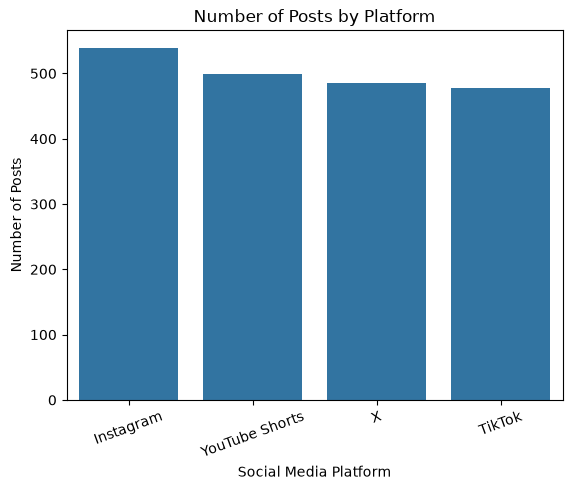

In [8]:
sns.countplot(data=df, x="platform")

plt.title("Number of Posts by Platform")
plt.xlabel("Social Media Platform")
plt.ylabel("Number of Posts")
plt.xticks(rotation=20)

plt.show()

In [11]:
platform_analysis = df.groupby("platform").agg(
    total_posts=("post_id", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum"),
    total_likes=("likes", "sum")
).reset_index()

platform_analysis["average_engagement_percent"] = (
    platform_analysis["average_engagement"] * 100
)

print(platform_analysis.sort_values(
    by="average_engagement",
    ascending=False
).round(2))

         platform  total_posts  average_engagement  total_views  total_likes  \
2               X          485                0.20   2049343414    117277465   
0       Instagram          539                0.15   2313892448    134988083   
1          TikTok          477                0.14   2079169996    116598016   
3  YouTube Shorts          499                0.14   2127313285    121794924   

   average_engagement_percent  
2                       20.10  
0                       14.82  
1                       14.38  
3                       13.98  


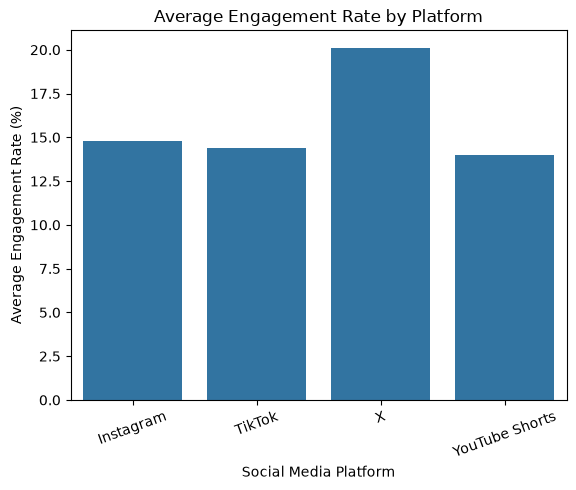

In [12]:
sns.barplot(
    data=platform_analysis,
    x="platform",
    y="average_engagement_percent"
)

plt.title("Average Engagement Rate by Platform")
plt.xlabel("Social Media Platform")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=20)
plt.show()

In [13]:
content_analysis = df.groupby("content_type").agg(
    total_posts=("content_type", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum"),
    total_likes=("likes", "sum")
).reset_index()

content_analysis["average_engagement_percent"] = (
    content_analysis["average_engagement"] * 100
)

content_analysis = content_analysis.sort_values(
    by="average_engagement_percent", ascending=False
)

print(content_analysis)

  content_type  total_posts  average_engagement  total_views  total_likes  \
2         text          488            0.183855   2049885306    121294723   
1        image          512            0.160950   2131432971    122476368   
3        video          472            0.149196   2139259641    118724134   
0     carousel          528            0.138553   2249141225    128163263   

   average_engagement_percent  
2                   18.385451  
1                   16.095000  
3                   14.919619  
0                   13.855265  


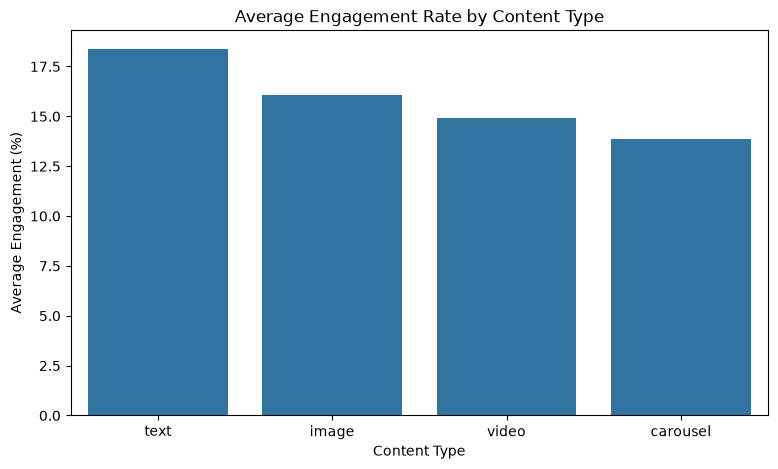

In [14]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=content_analysis,
    x="content_type",
    y="average_engagement_percent"
)

plt.title("Average Engagement Rate by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Average Engagement (%)")
plt.show()

In [15]:
weekday_analysis = df.groupby("weekday").agg(
    total_posts=("weekday", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum")
).reset_index()

weekday_analysis["average_engagement_percent"] = (
    weekday_analysis["average_engagement"] * 100
)

print(weekday_analysis)

     weekday  total_posts  average_engagement  total_views  \
0     Friday          266            0.120259   1143852250   
1     Monday          280            0.216048   1212450324   
2   Saturday          314            0.169687   1389055979   
3     Sunday          286            0.147431   1226251170   
4   Thursday          278            0.144060   1129468094   
5    Tuesday          288            0.186416   1270294486   
6  Wednesday          288            0.118187   1198346840   

   average_engagement_percent  
0                   12.025865  
1                   21.604786  
2                   16.968726  
3                   14.743077  
4                   14.406043  
5                   18.641632  
6                   11.818715  


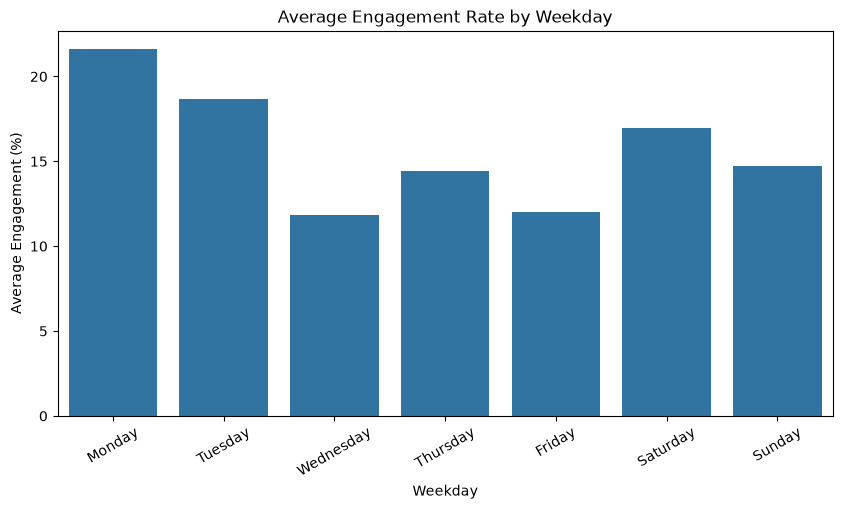

In [16]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(10,5))

sns.barplot(
    data=weekday_analysis,
    x="weekday",
    y="average_engagement_percent",
    order=weekday_order
)

plt.title("Average Engagement Rate by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Engagement (%)")
plt.xticks(rotation=30)
plt.show()

In [17]:
hour_analysis = df.groupby("hour").agg(
    total_posts=("hour", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum")
).reset_index()

hour_analysis["average_engagement_percent"] = (
    hour_analysis["average_engagement"] * 100
)

hour_analysis = hour_analysis.sort_values(
    by="average_engagement_percent",
    ascending=False
)

print(hour_analysis)

   hour  total_posts  average_engagement  total_views  \
0     0         2000            0.157852   8569719143   

   average_engagement_percent  
0                    15.78519  


In [18]:
print(df["post_datetime"].head(10))
print(df["post_datetime"].dtype)

0   2024-12-10
1   2024-10-13
2   2024-05-03
3   2024-08-04
4   2024-03-28
5   2024-11-01
6   2024-06-09
7   2024-07-26
8   2024-03-03
9   2024-10-05
Name: post_datetime, dtype: datetime64[us]
datetime64[us]


In [19]:
print(df["hour"].value_counts())
print(df["post_datetime"].min())
print(df["post_datetime"].max())

hour
0    2000
Name: count, dtype: int64
2024-01-01 00:00:00
2024-12-31 00:00:00


In [20]:
month_analysis = df.groupby("month").agg(
    total_posts=("month", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum"),
    total_likes=("likes", "sum")
).reset_index()

month_analysis["average_engagement_percent"] = (
    month_analysis["average_engagement"] * 100
)

print(month_analysis)

    month  total_posts  average_engagement  total_views  total_likes  \
0       1          157            0.223924    641743569     36755527   
1       2          181            0.154865    692916609     41381910   
2       3          171            0.117185    810818555     43603488   
3       4          189            0.132815    763476784     45664200   
4       5          151            0.127643    644790822     36354786   
5       6          162            0.343748    670684536     36396833   
6       7          185            0.117297    909233568     49724871   
7       8          148            0.148736    585029293     36551928   
8       9          168            0.136181    757268416     43125528   
9      10          153            0.117190    656263140     37569725   
10     11          175            0.156689    716194876     43929112   
11     12          160            0.127958    721298975     39600580   

    average_engagement_percent  
0                    22.392420

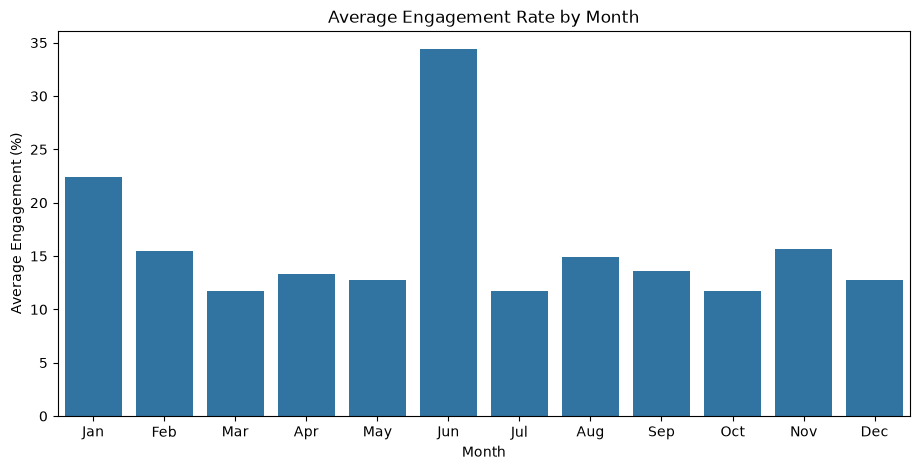

In [21]:
plt.figure(figsize=(11,5))

sns.barplot(
    data=month_analysis,
    x="month",
    y="average_engagement_percent"
)

plt.title("Average Engagement Rate by Month")
plt.xlabel("Month")
plt.ylabel("Average Engagement (%)")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])
plt.show()

In [22]:
viral_analysis = df.groupby("is_viral").agg(
    total_posts=("is_viral", "count"),
    average_engagement=("engagement_rate", "mean"),
    average_views=("views", "mean"),
    average_likes=("likes", "mean")
).reset_index()

print(viral_analysis)

   is_viral  total_posts  average_engagement  average_views  average_likes
0         0          602            0.339711   1.013173e+06   95912.504983
1         1         1398            0.079540   5.693697e+06  309670.357654


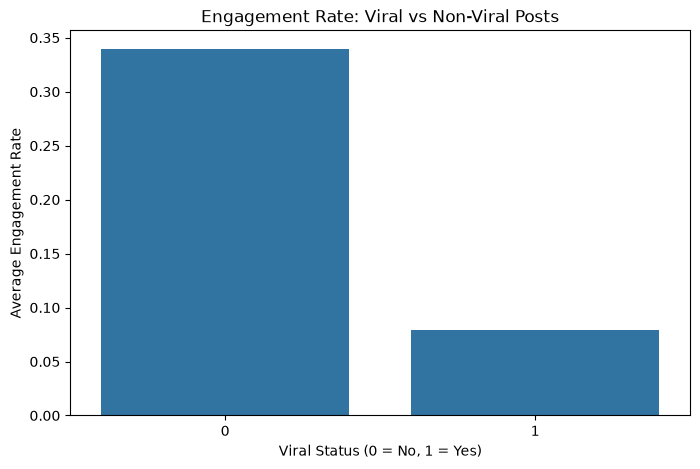

In [23]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=viral_analysis,
    x="is_viral",
    y="average_engagement"
)

plt.title("Engagement Rate: Viral vs Non-Viral Posts")
plt.xlabel("Viral Status (0 = No, 1 = Yes)")
plt.ylabel("Average Engagement Rate")
plt.show()

In [24]:
viral_platform = df.groupby("platform").agg(
    total_posts=("is_viral", "count"),
    viral_posts=("is_viral", "sum")
).reset_index()

viral_platform["viral_percentage"] = (
    viral_platform["viral_posts"] /
    viral_platform["total_posts"] * 100
)

print(viral_platform)

         platform  total_posts  viral_posts  viral_percentage
0       Instagram          539          382         70.871985
1          TikTok          477          335         70.230608
2               X          485          338         69.690722
3  YouTube Shorts          499          343         68.737475


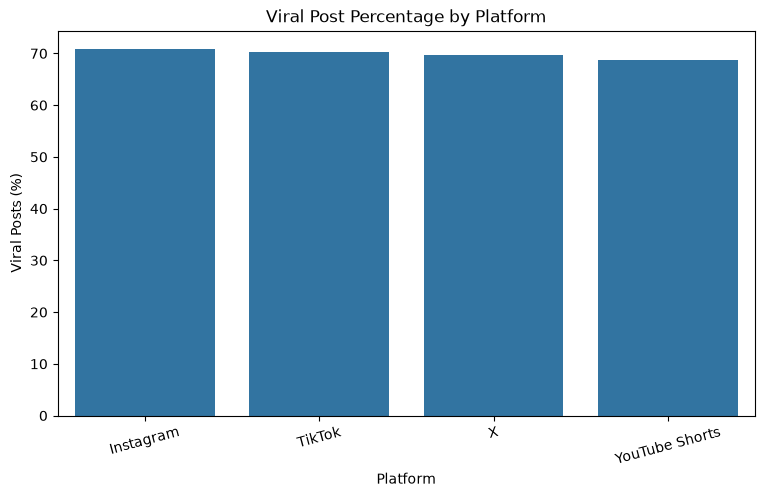

In [25]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=viral_platform,
    x="platform",
    y="viral_percentage"
)

plt.title("Viral Post Percentage by Platform")
plt.xlabel("Platform")
plt.ylabel("Viral Posts (%)")
plt.xticks(rotation=15)
plt.show()

In [26]:
viral_content = df.groupby("content_type").agg(
    total_posts=("is_viral", "count"),
    viral_posts=("is_viral", "sum")
).reset_index()

viral_content["viral_percentage"] = (
    viral_content["viral_posts"] /
    viral_content["total_posts"] * 100
)

viral_content = viral_content.sort_values(
    by="viral_percentage",
    ascending=False
)

print(viral_content)

  content_type  total_posts  viral_posts  viral_percentage
3        video          472          343         72.669492
0     carousel          528          381         72.159091
1        image          512          352         68.750000
2         text          488          322         65.983607


In [27]:
topic_analysis = df.groupby("topic").agg(
    total_posts=("topic", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum"),
    average_likes=("likes", "mean")
).reset_index()

topic_analysis["average_engagement_percent"] = (
    topic_analysis["average_engagement"] * 100
)

topic_analysis = topic_analysis.sort_values(
    by="average_engagement_percent",
    ascending=False
)

print(topic_analysis)

           topic  total_posts  average_engagement  total_views  average_likes  \
2      Lifestyle          315            0.204551   1391890668  243777.304762   
3       Politics          332            0.169947   1491599920  253944.000000   
5     Technology          331            0.162501   1333274542  235465.930514   
4         Sports          330            0.142332   1328034587  230314.430303   
0      Education          347            0.139346   1526734747  251105.792507   
1  Entertainment          345            0.132572   1498184679  256471.113043   

   average_engagement_percent  
2                   20.455143  
3                   16.994669  
5                   16.250091  
4                   14.233212  
0                   13.934582  
1                   13.257217  


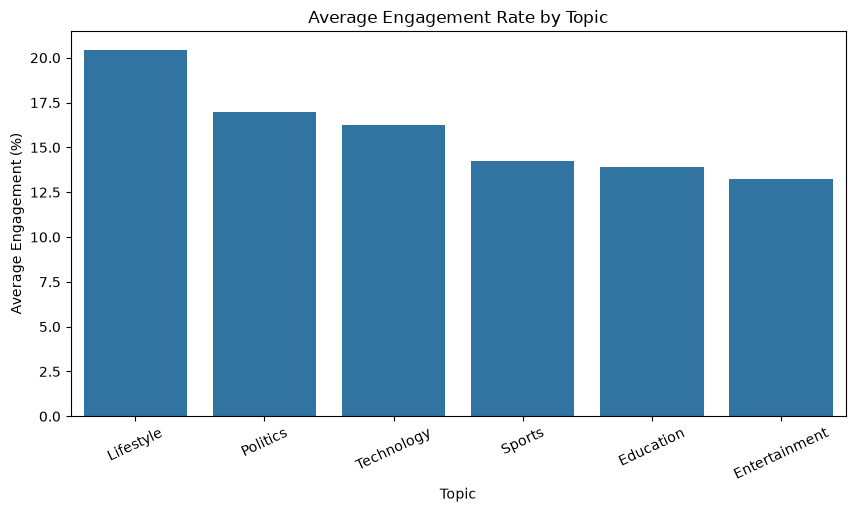

In [29]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=topic_analysis,
    x="topic",
    y="average_engagement_percent"
)

plt.title("Average Engagement Rate by Topic")
plt.xlabel("Topic")
plt.ylabel("Average Engagement (%)")
plt.xticks(rotation=25)
plt.show()

In [30]:
def sentiment_category(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["sentiment_score"].apply(sentiment_category)

sentiment_analysis = df.groupby("sentiment").agg(
    total_posts=("sentiment", "count"),
    average_engagement=("engagement_rate", "mean"),
    average_views=("views", "mean"),
    average_likes=("likes", "mean")
).reset_index()

sentiment_analysis["average_engagement_percent"] = (
    sentiment_analysis["average_engagement"] * 100
)

print(sentiment_analysis)

  sentiment  total_posts  average_engagement  average_views  average_likes  \
0  Negative          999            0.148833   4.203928e+06  240723.208208   
1  Positive         1001            0.166853   4.365629e+06  249926.076923   

   average_engagement_percent  
0                   14.883313  
1                   16.685265  


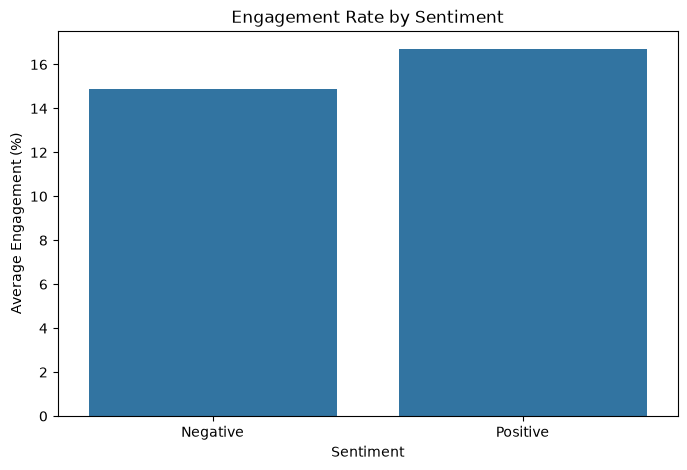

In [31]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=sentiment_analysis,
    x="sentiment",
    y="average_engagement_percent"
)

plt.title("Engagement Rate by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Engagement (%)")
plt.show()

In [32]:
language_analysis = df.groupby("language").agg(
    total_posts=("language", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum"),
    average_likes=("likes", "mean")
).reset_index()

language_analysis["average_engagement_percent"] = (
    language_analysis["average_engagement"] * 100
)

language_analysis = language_analysis.sort_values(
    by="average_engagement_percent",
    ascending=False
)

print(language_analysis)

  language  total_posts  average_engagement  total_views  average_likes  \
1       es          379            0.184383   1596936583  247321.419525   
2       fr          404            0.162973   1831709554  253746.383663   
3       hi          392            0.159291   1661776951  243657.392857   
0       en          420            0.143702   1792240727  245638.676190   
4       ur          405            0.141197   1687055328  236365.898765   

   average_engagement_percent  
1                   18.438311  
2                   16.297277  
3                   15.929056  
0                   14.370238  
4                   14.119679  


In [33]:
region_analysis = df.groupby("region").agg(
    total_posts=("region", "count"),
    average_engagement=("engagement_rate", "mean"),
    total_views=("views", "sum"),
    average_likes=("likes", "mean")
).reset_index()

region_analysis["average_engagement_percent"] = (
    region_analysis["average_engagement"] * 100
)

region_analysis = region_analysis.sort_values(
    by="average_engagement_percent",
    ascending=False
)

print(region_analysis)

     region  total_posts  average_engagement  total_views  average_likes  \
3        UK          385            0.195919   1665703156  249325.916883   
2  Pakistan          379            0.192406   1618919802  249704.068602   
4        US          428            0.147152   1773604676  239223.464953   
0    Brazil          402            0.132730   1751589049  247002.194030   
1     India          406            0.125652   1759902460  242235.573892   

   average_engagement_percent  
3                   19.591922  
2                   19.240580  
4                   14.715164  
0                   13.272985  
1                   12.565222  


In [34]:

# Analyze June engagement

june_data = df[df['month'] == 6]

print("June Posts:", len(june_data))
print("\nJune Engagement Statistics:")
print(june_data['engagement_rate'].describe())

print("\nTop 10 June Posts:")
print(june_data[['post_id', 'platform', 'topic',
                 'content_type', 'views', 'engagement_rate']]
      .sort_values(by='engagement_rate', ascending=False)
      .head(10))

print("\nJune vs Overall Median:")
print("June Median:", june_data['engagement_rate'].median())
print("Overall Median:", df['engagement_rate'].median())


June Posts: 162

June Engagement Statistics:
count    162.000000
mean       0.343748
std        1.546886
min        0.035700
25%        0.057675
50%        0.083450
75%        0.133325
max       12.573200
Name: engagement_rate, dtype: float64

Top 10 June Posts:
        post_id        platform       topic content_type   views  \
1170  SM_101170               X   Lifestyle         text   10500   
941   SM_100941               X  Technology        video    4380   
1779  SM_101779  YouTube Shorts    Politics        image    5516   
1988  SM_101988          TikTok  Technology        image   30132   
6     SM_100006               X   Education         text   65481   
1589  SM_101589       Instagram  Technology         text  159630   
1830  SM_101830  YouTube Shorts    Politics     carousel  114312   
122   SM_100122       Instagram      Sports     carousel  141720   
106   SM_100106       Instagram   Lifestyle        image  329400   
74    SM_100074       Instagram  Technology        image 

In [35]:

# Find extreme engagement values in June

print(
    june_data[
        june_data['engagement_rate'] > 1
    ][['post_id', 'platform', 'topic',
       'views', 'likes', 'comments',
       'shares', 'engagement_rate']]
    .sort_values(by='engagement_rate', ascending=False)
)


        post_id        platform       topic  views  likes  comments  shares  \
1170  SM_101170               X   Lifestyle  10500    420     37427   94172   
941   SM_100941               X  Technology   4380    292     36418   12817   
1779  SM_101779  YouTube Shorts    Politics   5516    394     32541   24597   
1988  SM_101988          TikTok  Technology  30132   5022      4397   52336   
6     SM_100006               X   Education  65481   2847       194   84655   

      engagement_rate  
1170          12.5732  
941           11.3075  
1779          10.4300  
1988           2.0495  
6              1.3393  


In [36]:

# Extract individual hashtags

df['hashtag_list'] = df['hashtags'].str.lower().str.split()

hashtag_df = df.explode('hashtag_list')

print(hashtag_df[['post_id', 'hashtag_list',
                  'engagement_rate', 'views']].head(10))


     post_id hashtag_list  engagement_rate    views
0  SM_100000        #tech           0.0598  2319102
0  SM_100000       #funny           0.0598  2319102
0  SM_100000       #music           0.0598  2319102
1  SM_100001        #news           0.0695  2538464
1  SM_100001         #fyp           0.0695  2538464
1  SM_100001       #funny           0.0695  2538464
1  SM_100001          #ai           0.0695  2538464
1  SM_100001    #trending           0.0695  2538464
2  SM_100002          #ai           0.1702  1051176
2  SM_100002        #news           0.1702  1051176


In [37]:

hashtag_analysis = hashtag_df.groupby('hashtag_list').agg(
    total_posts=('post_id', 'count'),
    average_engagement=('engagement_rate', 'mean'),
    total_views=('views', 'sum')
).reset_index()

hashtag_analysis['average_engagement_percent'] = (
    hashtag_analysis['average_engagement'] * 100
)

hashtag_analysis = hashtag_analysis.sort_values(
    by='average_engagement',
    ascending=False
)

print("Top 10 Hashtags:")
print(hashtag_analysis.head(10))

print("\nMost Used Hashtags:")
print(
    hashtag_analysis.sort_values(
        by='total_posts',
        ascending=False
    ).head(10)
)


Top 10 Hashtags:
  hashtag_list  total_posts  average_engagement  total_views  \
1       #funny          876            0.180698   3720435405   
0          #ai          856            0.176088   3644466672   
4        #news          867            0.170337   3668530244   
6    #trending          905            0.162333   3832594287   
7       #viral          876            0.158277   3741564763   
5        #tech          845            0.142885   3765586790   
2         #fyp          834            0.138901   3638621726   
3       #music          888            0.131267   3900453165   

   average_engagement_percent  
1                   18.069840  
0                   17.608820  
4                   17.033749  
6                   16.233326  
7                   15.827740  
5                   14.288462  
2                   13.890072  
3                   13.126745  

Most Used Hashtags:
  hashtag_list  total_posts  average_engagement  total_views  \
6    #trending          905      

In [38]:

# Correlation Analysis

numeric_df = df[['views', 'likes', 'comments', 'shares',
                 'engagement_rate', 'sentiment_score',
                 'is_viral']]

correlation = numeric_df.corr()

print(correlation.round(2))


                 views  likes  comments  shares  engagement_rate  \
views             1.00   0.77     -0.02   -0.01            -0.21   
likes             0.77   1.00     -0.02   -0.00            -0.20   
comments         -0.02  -0.02      1.00    0.01             0.05   
shares           -0.01  -0.00      0.01    1.00             0.04   
engagement_rate  -0.21  -0.20      0.05    0.04             1.00   
sentiment_score   0.03   0.04     -0.01   -0.00             0.01   
is_viral          0.66   0.68     -0.02   -0.00            -0.22   

                 sentiment_score  is_viral  
views                       0.03      0.66  
likes                       0.04      0.68  
comments                   -0.01     -0.02  
shares                     -0.00     -0.00  
engagement_rate             0.01     -0.22  
sentiment_score             1.00      0.01  
is_viral                    0.01      1.00  


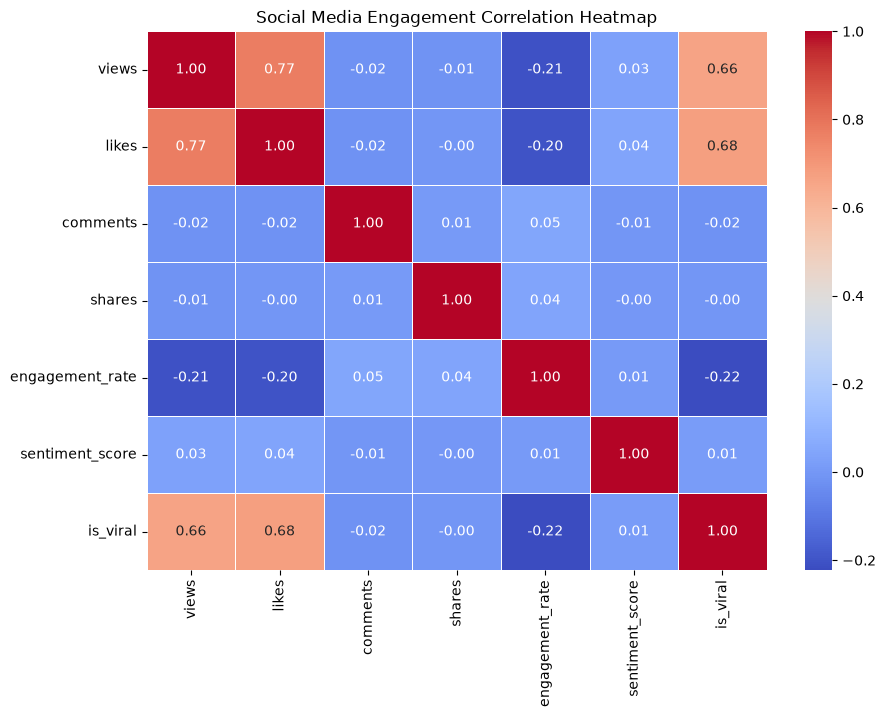

In [39]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)

plt.title('Social Media Engagement Correlation Heatmap')
plt.show()


In [40]:
print(hashtag_analysis.sort_values(
    by='total_posts', ascending=False
)[['hashtag_list', 'total_posts']].to_string(index=False))

hashtag_list  total_posts
   #trending          905
      #music          888
      #viral          876
      #funny          876
       #news          867
         #ai          856
       #tech          845
        #fyp          834


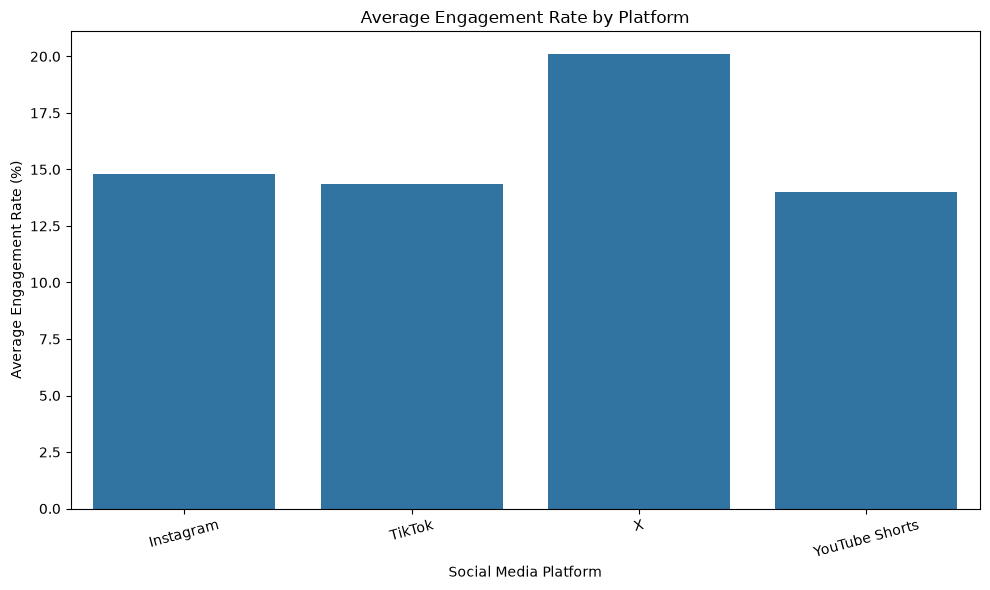

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

platform_data = df.groupby('platform', as_index=False).agg(
    average_engagement=('engagement_rate', 'mean')
)

platform_data['average_engagement'] *= 100

plt.figure(figsize=(10, 6))

sns.barplot(
    data=platform_data,
    x='platform',
    y='average_engagement'
)

plt.title('Average Engagement Rate by Platform')
plt.xlabel('Social Media Platform')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


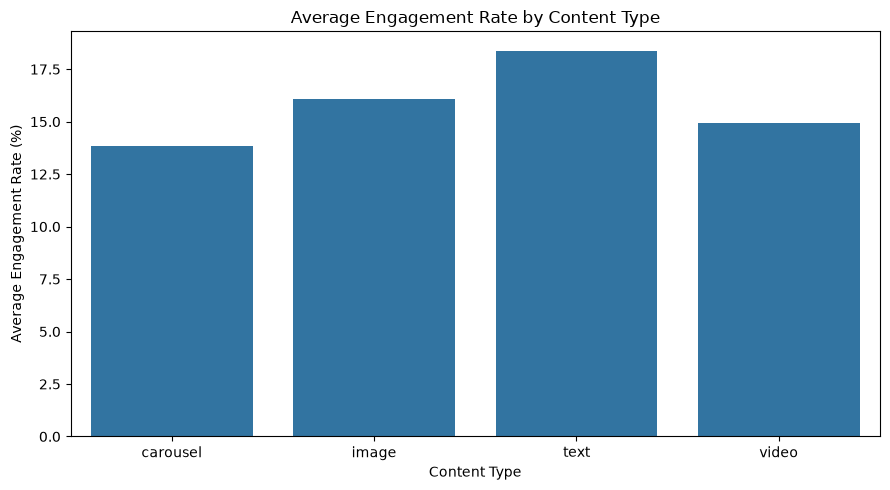

In [43]:

content_data = df.groupby('content_type', as_index=False).agg(
    average_engagement=('engagement_rate', 'mean')
)

content_data['average_engagement'] *= 100

plt.figure(figsize=(9, 5))

sns.barplot(
    data=content_data,
    x='content_type',
    y='average_engagement'
)

plt.title('Average Engagement Rate by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Average Engagement Rate (%)')

plt.tight_layout()
plt.show()


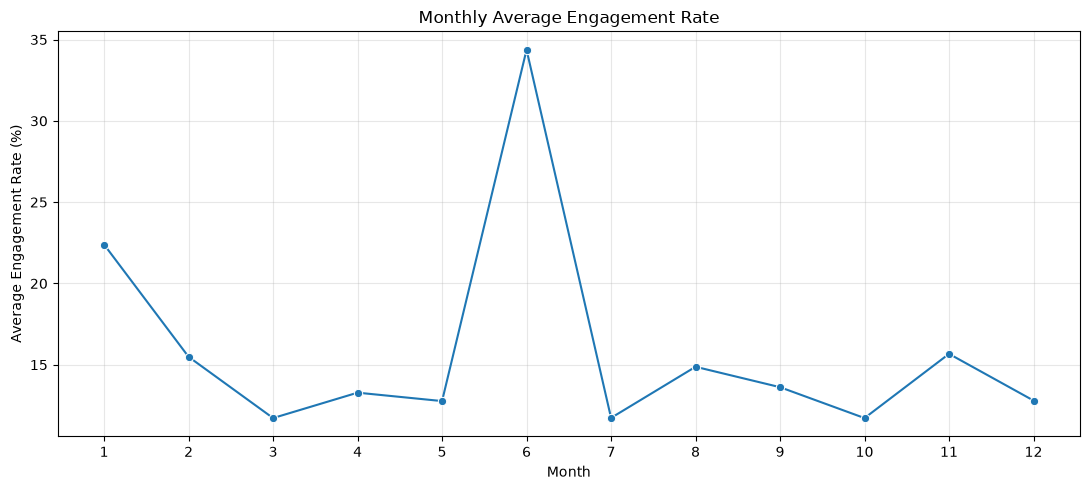

In [44]:

monthly_data = df.groupby('month', as_index=False).agg(
    average_engagement=('engagement_rate', 'mean')
)

monthly_data['average_engagement'] *= 100

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=monthly_data,
    x='month',
    y='average_engagement',
    marker='o'
)

plt.title('Monthly Average Engagement Rate')
plt.xlabel('Month')
plt.ylabel('Average Engagement Rate (%)')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


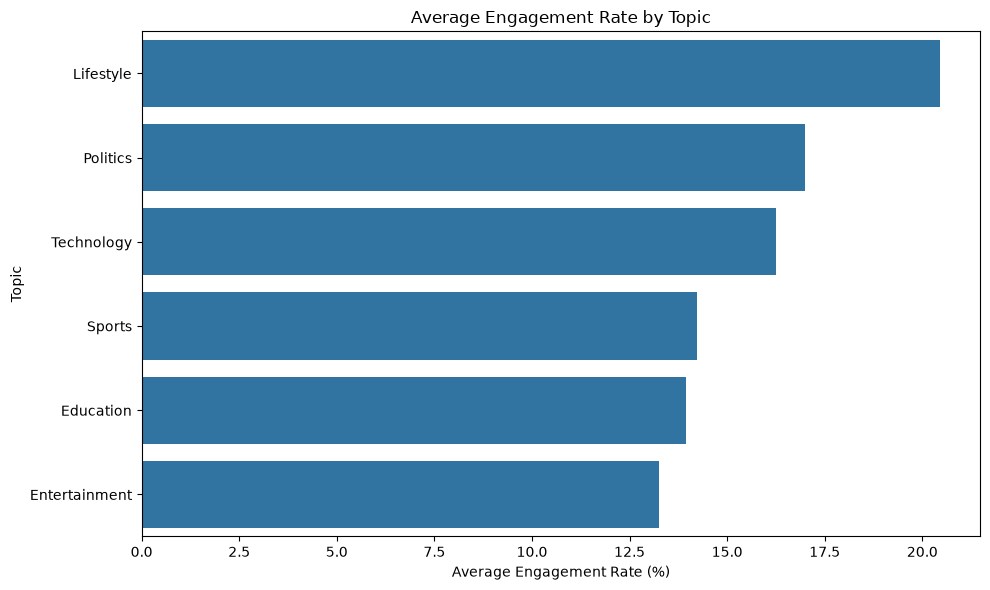

In [45]:

topic_data = df.groupby('topic', as_index=False).agg(
    average_engagement=('engagement_rate', 'mean')
)

topic_data['average_engagement'] *= 100

topic_data = topic_data.sort_values(
    by='average_engagement',
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=topic_data,
    x='average_engagement',
    y='topic'
)

plt.title('Average Engagement Rate by Topic')
plt.xlabel('Average Engagement Rate (%)')
plt.ylabel('Topic')

plt.tight_layout()
plt.show()


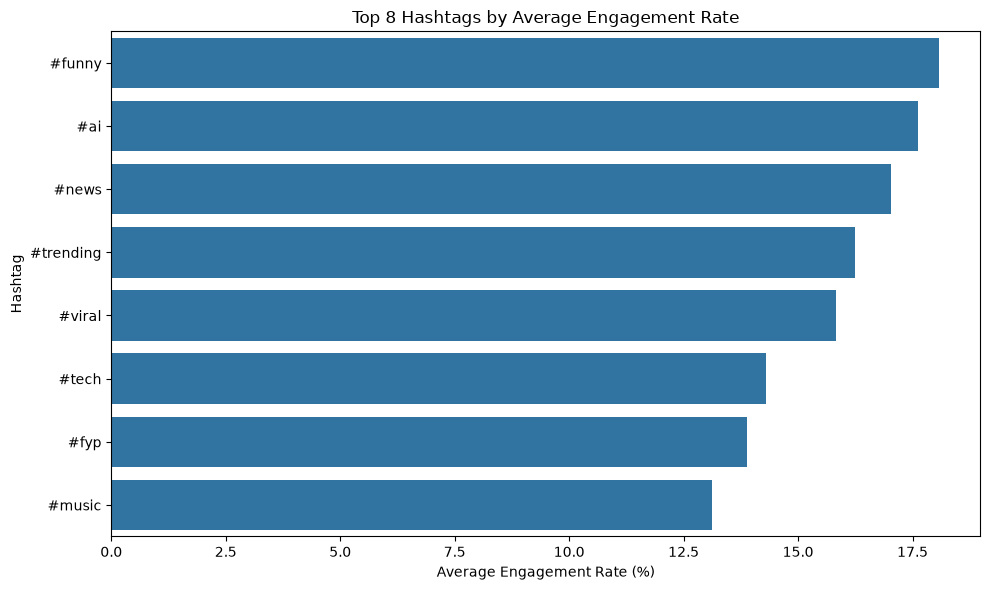

In [46]:

top_hashtags = hashtag_analysis.sort_values(
    by='average_engagement',
    ascending=False
).head(8)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_hashtags,
    x='average_engagement_percent',
    y='hashtag_list'
)

plt.title('Top 8 Hashtags by Average Engagement Rate')
plt.xlabel('Average Engagement Rate (%)')
plt.ylabel('Hashtag')

plt.tight_layout()
plt.show()


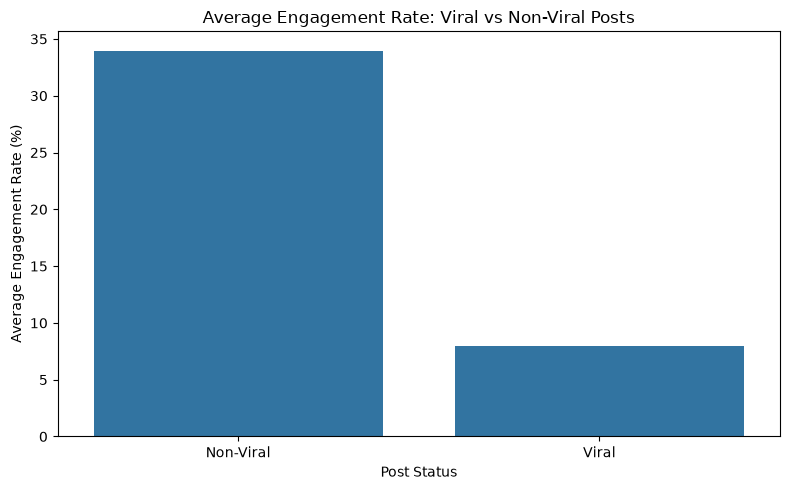

In [47]:

viral_data = df.groupby('is_viral', as_index=False).agg(
    average_engagement=('engagement_rate', 'mean'),
    total_posts=('post_id', 'count')
)

viral_data['average_engagement'] *= 100

viral_data['viral_status'] = viral_data['is_viral'].map({
    0: 'Non-Viral',
    1: 'Viral'
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=viral_data,
    x='viral_status',
    y='average_engagement'
)

plt.title('Average Engagement Rate: Viral vs Non-Viral Posts')
plt.xlabel('Post Status')
plt.ylabel('Average Engagement Rate (%)')

plt.tight_layout()
plt.show()
